# 13. Фінальне порівняння моделей

**Етап 13 з 13** · NASA C-MAPSS FD001 · підсумок дослідження


## 1. Як читати порівняння

- **Raw official test** — головна таблиця для чесного зіставлення моделей.
- **Capped at 125** — додаткова прикладна оцінка; її не можна напряму ранжувати разом з raw.
- Результати validation і official test не змішуються.
- Калібрована q20 навчалася за іншим split (64/16/20), тому її коректно порівнювати насамперед із retrained base з того самого запуску.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
plt.style.use("seaborn-v0_8-whitegrid")


## 2. Raw official-test результати


In [2]:
raw_results = pd.DataFrame([
    {"model": "LSTM w80", "protocol": "full-window", "MAE": 10.430, "RMSE": 16.288, "R2": 0.846, "NASA_Score": np.nan, "over_rate": np.nan, "source": "09_official_test_w80"},
    {"model": "XGBoost", "protocol": "last-cycle tabular", "MAE": 15.571, "RMSE": 22.180, "R2": 0.715, "NASA_Score": np.nan, "over_rate": np.nan, "source": "09_official_test_w80"},
    {"model": "1D-CNN w80", "protocol": "full-window", "MAE": 15.884, "RMSE": 28.043, "R2": 0.545, "NASA_Score": np.nan, "over_rate": np.nan, "source": "09_official_test_w80"},
    {"model": "LSTM partial-history", "protocol": "prefix training", "MAE": 13.118, "RMSE": 20.376, "R2": 0.760, "NASA_Score": np.nan, "over_rate": np.nan, "source": "10_partial_history_training"},
    {"model": "CNN partial-history", "protocol": "prefix training", "MAE": 17.661, "RMSE": 25.757, "R2": 0.616, "NASA_Score": np.nan, "over_rate": np.nan, "source": "10_partial_history_training"},
    {"model": "Conservative LSTM q20", "protocol": "prefix + quantile", "MAE": 9.913, "RMSE": 15.060, "R2": 0.869, "NASA_Score": 466.107, "over_rate": 0.460, "source": "11_conservative_lstm_q20"},
]).sort_values("MAE").reset_index(drop=True)

display(raw_results.round(3))


,model,protocol,MAE,RMSE,R2,NASA_Score,over_rate,source
0,Conservative LSTM q20,prefix + quantile,9.913,15.060,0.869,466.107,0.46,11_conservative_lstm_q20
1,LSTM w80,full-window,10.430,16.288,0.846,NaN,NaN,09_official_test_w80
2,LSTM partial-history,prefix training,13.118,20.376,0.760,NaN,NaN,10_partial_history_training
3,XGBoost,last-cycle tabular,15.571,22.180,0.715,NaN,NaN,09_official_test_w80
4,1D-CNN w80,full-window,15.884,28.043,0.545,NaN,NaN,09_official_test_w80
5,CNN partial-history,prefix training,17.661,25.757,0.616,NaN,NaN,10_partial_history_training


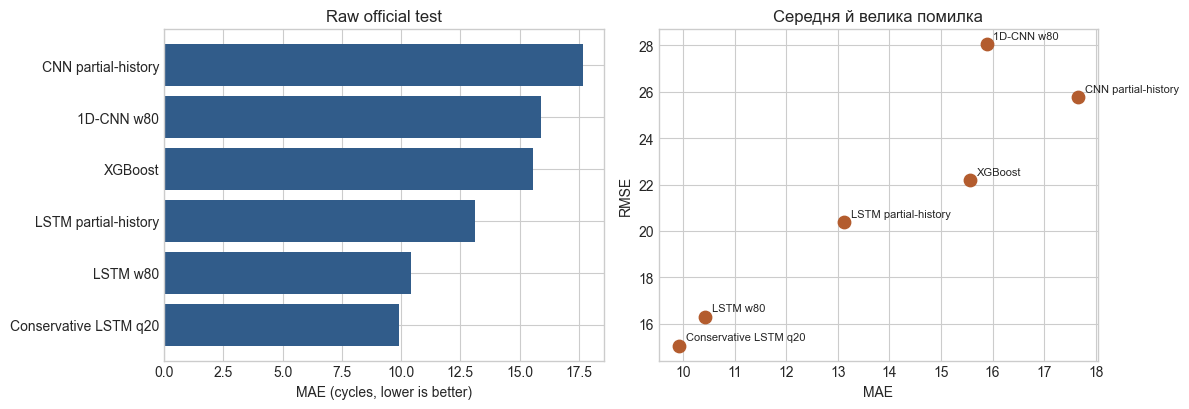

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ordered = raw_results.sort_values("MAE", ascending=True)
axes[0].barh(ordered["model"], ordered["MAE"], color="#315c8a")
axes[0].set_xlabel("MAE (cycles, lower is better)")
axes[0].set_title("Raw official test")
axes[1].scatter(raw_results["MAE"], raw_results["RMSE"], s=80, color="#b35c2e")
for _, row in raw_results.iterrows():
    axes[1].annotate(row["model"], (row["MAE"], row["RMSE"]), xytext=(5, 4), textcoords="offset points", fontsize=8)
axes[1].set_xlabel("MAE")
axes[1].set_ylabel("RMSE")
axes[1].set_title("Середня й велика помилка")
plt.tight_layout()
plt.show()


## 3. q20: ціна додаткової обережності


In [4]:
calibration_results = pd.DataFrame([
    {"model": "Retrained base q20", "MAE": 11.677, "RMSE": 17.456, "R2": 0.824, "NASA_Score": 783.084, "over_rate": 0.30, "coverage": 0.70, "mean_bias": -2.031},
    {"model": "Calibrated q20", "MAE": 12.801, "RMSE": 17.881, "R2": 0.815, "NASA_Score": 703.643, "over_rate": 0.24, "coverage": 0.76, "mean_bias": -4.372},
])
display(calibration_results.round(3))

delta = calibration_results.set_index("model").loc["Calibrated q20"] - calibration_results.set_index("model").loc["Retrained base q20"]
display(delta.to_frame("calibrated_minus_base").round(3))


,model,MAE,RMSE,R2,NASA_Score,over_rate,coverage,mean_bias
0,Retrained base q20,11.677,17.456,0.824,783.084,0.30,0.70,-2.031
1,Calibrated q20,12.801,17.881,0.815,703.643,0.24,0.76,-4.372


,calibrated_minus_base
MAE,1.124
RMSE,0.425
R2,-0.009
NASA_Score,-79.441
over_rate,-0.060
coverage,0.060
mean_bias,-2.341


## 4. Фінальний вибір

**Найкраща точність:** `Conservative LSTM q20` з окремого q20 запуску — MAE 9.913, RMSE 15.060 і NASA Score 466.107 на raw official test.

**Найкращий контроль завищення в каліброваній парі:** `Calibrated q20` — overestimation rate зменшився з 0.30 до 0.24, coverage зріс з 0.70 до 0.76, NASA Score знизився з 783.084 до 703.643. Ціна цього рішення — MAE зріс приблизно на 1.12 циклу.

Для демонстрації системи я б залишив обидва артефакти: q20 як основну модель точності та calibrated q20 як safety-режим. Остаточний вибір залежить від вартості хибного завищення RUL у конкретній установці.
